# 03.1 — Train, evaluate, and enforce threshold monotonicity

This notebook preserves Notebook 03's original climatology, LR, RF, and GBT
comparison, training splits, calibration policy, metrics, figures, and saved
artifacts. It additionally compares two monotonic probability estimators:
calibrated GBT-B with threshold-wise isotonic projection, and native Spark
MLlib multinomial logistic regression over nine rainfall-amount classes with
a training-derived within-bin empirical CDF.

The original notebook sections run first. The monotonic extension uses a fixed
2% training-time sample and a deterministic 0.2% 2024 evaluation-time sample;
it does not use the holdout to choose hyperparameters, bin boundaries, or
post-processing. All methods are evaluated on the same station/time/threshold
queries. This is a retrospective event-time study, not a live forecasting API.

**Run order:** Notebook 00 (new run prefix), 01, 02, then this notebook on
Dataproc Python 3 / Spark 3.5.3. The original Notebook 03 need not be run
separately. Do not reuse the completed run prefix.


In [1]:
import json
import math
import os
import subprocess
import tempfile
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
from pyspark import StorageLevel
from pyspark.ml import Pipeline
from pyspark.ml.classification import (
    GBTClassifier,
    LogisticRegression,
    RandomForestClassifier,
)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import Imputer, OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import IsotonicRegression
from pyspark.sql import SparkSession, Window, functions as F


In [ ]:
BUCKET = os.environ.get("BUCKET", "dsa5208-rainfall-project-2-data")
RUN_ID = os.environ.get("RUN_ID", "20261018-monotonic-01")
ROOT = f"gs://{BUCKET}/runs/{RUN_ID}"
MODEL_ROOT = f"{ROOT}/models"
RESULTS_ROOT = f"{ROOT}/results"
config_result = subprocess.run(
    ["gcloud", "storage", "cat", f"{ROOT}/config/experiment.json"],
    check=True, capture_output=True, text=True,
)
config = json.loads(config_result.stdout)

spark = SparkSession.builder.appName("dsa5208-rainfall-models").getOrCreate()
spark.conf.set("spark.sql.shuffle.partitions", str(config["shuffle_partitions"]))
spark.conf.set("spark.sql.session.timeZone", config["timezone"])
spark.conf.set("spark.sql.ansi.enabled", "false")
actual_spark_conf = {
    name: spark.conf.get(name)
    for name in ("spark.sql.shuffle.partitions", "spark.sql.session.timeZone", "spark.sql.ansi.enabled")
}
assert actual_spark_conf["spark.sql.shuffle.partitions"] == str(config["shuffle_partitions"])
assert actual_spark_conf["spark.sql.session.timeZone"] == config["timezone"]
assert actual_spark_conf["spark.sql.ansi.enabled"] == "false"
display({"actual_spark_conf": actual_spark_conf})

assert config["availability_mode"] == "retrospective_event_time"
assert config["alignment_tolerance_seconds"] == 0
assert config["interval_semantics_confirmed"] or config["interval_end_assumption_accepted"]


Bucket: dsa5208-rainfall-project-2-data
Run ID: 20261018-monotonic-01
Root: gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/17 23:17:45 INFO SparkEnv: Registering MapOutputTracker
26/10/17 23:17:45 INFO SparkEnv: Registering BlockManagerMaster
26/10/17 23:17:45 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/10/17 23:17:45 INFO SparkEnv: Registering OutputCommitCoordinator


{'actual_spark_conf': {'spark.sql.shuffle.partitions': '64',
  'spark.sql.session.timeZone': 'Asia/Singapore',
  'spark.sql.ansi.enabled': 'false'}}

In [3]:
BASE_FEATURES = ["hour_sin", "hour_cos", "day_sin", "day_cos", "threshold_mm"]

def feature_columns(variant):
    if variant == "A":
        return list(BASE_FEATURES)
    if variant != "B":
        raise ValueError("Feature variant must be A or B.")
    columns = BASE_FEATURES + ["rain_current"]
    for minutes in config["lag_minutes"]:
        columns += [f"lag_{minutes}", f"lag_{minutes}_missing"]
    for minutes in config["rolling_minutes"]:
        columns += [
            f"sum_{minutes}", f"max_{minutes}", f"wet_count_{minutes}",
            f"count_{minutes}", f"coverage_{minutes}",
        ]
    return columns


In [4]:
def threshold_units(value):
    scaled = Decimal(str(value)) * config["rainfall_integer_scale"]
    if scaled != scaled.to_integral_value():
        raise ValueError(f"Threshold {value} exceeds the stored numeric precision.")
    return int(scaled)

def expand_thresholds(frame, thresholds=None):
    values = thresholds or config["thresholds_mm"]
    rows = [(float(value), threshold_units(value)) for value in values]
    grid = spark.createDataFrame(rows, "threshold_mm double, threshold_units long")
    expanded = frame.crossJoin(F.broadcast(grid))
    return expanded.withColumn(
        "label", (F.col("future_units") > F.col("threshold_units")).cast("double")
    )


In [5]:
def deterministic_sample(frame, fraction):
    if fraction >= 1:
        return frame
    bucket = F.pmod(
        F.xxhash64("station_id", "epoch", F.lit(config["sampling_seed"])),
        F.lit(1_000_000),
    )
    return frame.where(bucket < int(fraction * 1_000_000))

def mark_unseen(frame, seen_stations):
    return (
        frame.join(seen_stations.withColumn("_seen", F.lit(True)), "station_id", "left")
        .withColumn("unseen_station", F.col("_seen").isNull())
        .drop("_seen")
    )


In [6]:
base = spark.read.parquet(f"{ROOT}/base_features")
train_base = base.where("split = 'train' AND label_valid")
selection_base = base.where("split = 'selection' AND label_valid")
calibration_base = base.where("split = 'calibration' AND label_valid")

for name, frame in [
    ("train", train_base),
    ("selection", selection_base),
    ("calibration", calibration_base),
]:
    if frame.limit(1).count() == 0:
        raise ValueError(f"The {name} split has no valid six-reading targets.")


In [7]:
training_stations = train_base.select("station_id").distinct().persist()
threshold_values = config["thresholds_mm"]
support_counts = train_base.agg(
    F.count("*").alias("n"),
    *[
        F.sum(
            (F.col("future_units") > F.lit(threshold_units(value))).cast("long")
        ).alias(f"positive_{index}")
        for index, value in enumerate(threshold_values)
    ],
).first().asDict()
support = [
    {
        "threshold_mm": float(value),
        "n": int(support_counts["n"]),
        "positives": int(support_counts[f"positive_{index}"] or 0),
    }
    for index, value in enumerate(threshold_values)
]
primary_thresholds = sorted(
    row["threshold_mm"]
    for row in support
    if config["primary_threshold_min_positives"] <= row["positives"] < row["n"]
)
if not primary_thresholds:
    raise ValueError("No threshold has sufficient positive and negative training support.")
display(support)


26/10/17 23:18:17 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


[{'threshold_mm': 0.2, 'n': 34542285, 'positives': 1515802},
 {'threshold_mm': 0.5, 'n': 34542285, 'positives': 1160284},
 {'threshold_mm': 1.0, 'n': 34542285, 'positives': 804747},
 {'threshold_mm': 2.0, 'n': 34542285, 'positives': 535577},
 {'threshold_mm': 5.0, 'n': 34542285, 'positives': 279801},
 {'threshold_mm': 10.0, 'n': 34542285, 'positives': 134448}]

In [8]:
pilot = expand_thresholds(
    deterministic_sample(train_base, config["pilot_fraction"])
).persist(StorageLevel.DISK_ONLY)
train = expand_thresholds(
    deterministic_sample(train_base, config["final_train_fraction"])
).persist(StorageLevel.DISK_ONLY)
selection = mark_unseen(expand_thresholds(selection_base), training_stations).persist(
    StorageLevel.DISK_ONLY
)


26/10/17 23:18:23 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/17 23:18:23 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/10/17 23:18:23 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/17 23:18:24 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [9]:
def histogram(keys):
    return (
        train_base.groupBy(*keys, "future_units")
        .count()
        .withColumnRenamed("count", "frequency")
    )

station_hist = histogram(["station_id", "month", "hour"])
month_hist = histogram(["month", "hour"])
global_hist = histogram([])
climatology_root = f"{MODEL_ROOT}/climatology"
station_hist.write.mode("overwrite").parquet(f"{climatology_root}/station_hour")
month_hist.write.mode("overwrite").parquet(f"{climatology_root}/month_hour")
global_hist.write.mode("overwrite").parquet(f"{climatology_root}/global")

display({
    "pilot_base_rows": pilot.select("station_id", "epoch").distinct().count(),
    "final_train_base_rows": train.select("station_id", "epoch").distinct().count(),
    "selection_rows_after_threshold_expansion": selection.count(),
    "primary_thresholds_mm": primary_thresholds,
})


{'pilot_base_rows': 173478,
 'final_train_base_rows': 690699,
 'selection_rows_after_threshold_expansion': 19952994,
 'primary_thresholds_mm': [0.2, 0.5, 1.0, 2.0, 5.0, 10.0]}

In [10]:
def global_climatology_probability(query):
    threshold_grid = query.select("threshold_mm", "threshold_units").distinct()
    return (
        threshold_grid.crossJoin(global_hist)
        .groupBy("threshold_mm", "threshold_units")
        .agg(
            F.sum("frequency").alias("global_n"),
            F.sum(
                F.when(
                    F.col("future_units") > F.col("threshold_units"),
                    F.col("frequency"),
                ).otherwise(0)
            ).alias("global_positives"),
        )
        .withColumn("global_p", F.col("global_positives") / F.col("global_n"))
    )


In [11]:
def month_hour_climatology_probability(query, global_p):
    smoothing = config["climatology_smoothing"]
    return (
        query.select("month", "hour", "threshold_mm", "threshold_units")
        .distinct()
        .join(month_hist, ["month", "hour"], "left")
        .groupBy("month", "hour", "threshold_mm", "threshold_units")
        .agg(
            F.coalesce(F.sum("frequency"), F.lit(0)).alias("broad_n"),
            F.coalesce(
                F.sum(
                    F.when(
                        F.col("future_units") > F.col("threshold_units"),
                        F.col("frequency"),
                    ).otherwise(0)
                ),
                F.lit(0),
            ).alias("broad_positives"),
        )
        .join(
            global_p.select("threshold_mm", "threshold_units", "global_p"),
            ["threshold_mm", "threshold_units"],
        )
        .withColumn(
            "broad_p",
            (F.col("broad_positives") + smoothing * F.col("global_p"))
            / (F.col("broad_n") + smoothing),
        )
    )


In [12]:
def station_hour_climatology_probability(query, broad):
    keys = ["station_id", "month", "hour", "threshold_mm", "threshold_units"]
    smoothing = config["climatology_smoothing"]
    return (
        query.join(station_hist, ["station_id", "month", "hour"], "left")
        .groupBy(*keys)
        .agg(
            F.coalesce(F.sum("frequency"), F.lit(0)).alias("local_n"),
            F.coalesce(
                F.sum(
                    F.when(
                        F.col("future_units") > F.col("threshold_units"),
                        F.col("frequency"),
                    ).otherwise(0)
                ),
                F.lit(0),
            ).alias("local_positives"),
        )
        .join(
            broad.select(
                "month", "hour", "threshold_mm", "threshold_units", "broad_p"
            ),
            ["month", "hour", "threshold_mm", "threshold_units"],
        )
        .withColumn(
            "p",
            (F.col("local_positives") + smoothing * F.col("broad_p"))
            / (F.col("local_n") + smoothing),
        )
    )


In [13]:
SCORE_COLUMNS = [
    "station_id", "epoch", "local_date", "month", "hour",
    "threshold_mm", "threshold_units", "label", "unseen_station", "onset",
]

def climatology_scores(queries):
    keys = ["station_id", "month", "hour", "threshold_mm", "threshold_units"]
    query = queries.select(*keys).distinct()
    global_p = global_climatology_probability(query)
    broad = month_hour_climatology_probability(query, global_p)
    local = station_hour_climatology_probability(query, broad)
    scores = queries.join(local.select(*keys, "p"), keys, "left")
    return scores.select(*SCORE_COLUMNS, "p")


In [14]:
def feature_preprocessing_stages(variant):
    numeric = feature_columns(variant)
    imputed = [f"{name}_imputed" for name in numeric]
    return [
        StringIndexer(inputCol="station_id", outputCol="station_index", handleInvalid="keep"),
        OneHotEncoder(
            inputCols=["station_index"], outputCols=["station_vector"],
            handleInvalid="keep", dropLast=False,
        ),
        Imputer(inputCols=numeric, outputCols=imputed, strategy="median"),
        VectorAssembler(inputCols=["station_vector", *imputed], outputCol="assembled"),
    ]


In [15]:
def build_pipeline(algorithm, parameters, variant):
    stages = feature_preprocessing_stages(variant)

    if algorithm == "lr":
        stages += [
            StandardScaler(
                inputCol="assembled",
                outputCol="features",
                withMean=False,
                withStd=True,
            ),
            LogisticRegression(
                featuresCol="features",
                labelCol="label",
                maxIter=50,
                elasticNetParam=0.0,
                **parameters,
            ),
        ]

    elif algorithm == "rf":
        stages += [
            RandomForestClassifier(
                featuresCol="assembled",
                labelCol="label",
                seed=config["sampling_seed"],
                maxBins=64,
                **parameters,
            ),
        ]

    elif algorithm == "gbt":
        stages += [
            GBTClassifier(
                featuresCol="assembled",
                labelCol="label",
                seed=config["sampling_seed"],
                maxBins=64,
                **parameters,
            ),
        ]

    else:
        raise ValueError(f"Unknown algorithm: {algorithm}")

    return Pipeline(stages=stages)


In [16]:
def score_model(model, frame):
    transformed = model.transform(frame)
    return transformed.select(
        *SCORE_COLUMNS,
        vector_to_array("probability")[1].alias("p"),
    )


In [17]:
REFERENCE_CUTOFF = 0.5

def add_reference_classification_metrics(row):
    positives = int(row["positives"] or 0)
    precision = row["tp"] / (row["tp"] + row["fp"]) if row["tp"] + row["fp"] else None
    recall = row["tp"] / (row["tp"] + row["fn"]) if row["tp"] + row["fn"] else None
    row.update(
        positives=positives,
        prevalence=positives / row["n"] if row["n"] else None,
        reference_cutoff=REFERENCE_CUTOFF,
        precision=precision,
        recall=recall,
        f1=(
            2 * precision * recall / (precision + recall)
            if precision is not None and recall is not None and precision + recall
            else None
        ),
    )
    return row


In [18]:
def probability_metrics(scores):
    p = F.col("p")
    y = F.col("label")
    row = scores.agg(
        F.count("*").alias("n"),
        F.sum(y).alias("positives"),
        F.avg(F.pow(p - y, 2)).alias("brier"),
        F.sum(((p >= REFERENCE_CUTOFF) & (y == 1)).cast("long")).alias("tp"),
        F.sum(((p >= REFERENCE_CUTOFF) & (y == 0)).cast("long")).alias("fp"),
        F.sum(((p < REFERENCE_CUTOFF) & (y == 1)).cast("long")).alias("fn"),
    ).first().asDict()

    positives = int(row["positives"] or 0)
    n = row["n"]
    row["pr_auc"] = None
    if 0 < positives < n:
        evaluator = BinaryClassificationEvaluator(
            rawPredictionCol="p", labelCol="label", metricName="areaUnderPR",
            numBins=config["auc_num_bins"],
        )
        row["pr_auc"] = evaluator.evaluate(scores)
    return add_reference_classification_metrics(row)


In [19]:
def threshold_metrics(scores, thresholds):
    return [
        {"threshold_mm": float(value), **probability_metrics(
            scores.where(F.col("threshold_mm") == float(value))
        )}
        for value in thresholds
    ]


In [20]:
def reliability_table(scores):
    bins = config["calibration_bins"]
    return (
        scores.withColumn(
            "bin", F.least(F.floor(F.col("p") * bins), F.lit(bins - 1)).cast("int")
        )
        .groupBy("threshold_mm", "bin")
        .agg(
            F.avg("p").alias("predicted_probability"),
            F.avg("label").alias("observed_frequency"),
            F.count("*").alias("n"),
        )
    )

def weighted_ece(scores):
    bins = reliability_table(scores)
    return bins.withColumn(
        "weighted_error",
        F.abs(F.col("predicted_probability") - F.col("observed_frequency")) * F.col("n"),
    ).agg((F.sum("weighted_error") / F.sum("n")).alias("ece")).first()["ece"]



In [21]:
def selection_objective(record):
    supported = [
        row for row in record["metrics"]
        if row["threshold_mm"] in primary_thresholds and row["pr_auc"] is not None
    ]
    if not supported:
        return None, math.inf
    return (
        sum(row["pr_auc"] for row in supported) / len(supported),
        sum(row["brier"] for row in supported) / len(supported),
    )


In [22]:
def choose_candidate(records):
    ranked = []
    for record in records:
        pr_auc, brier = selection_objective(record)
        ranked.append((record, pr_auc, brier))
    eligible = [item for item in ranked if item[1] is not None]
    if not eligible:
        raise ValueError("No candidate has supported PR-AUC values.")

    best_pr_auc = max(item[1] for item in eligible)
    shortlist = [
        item for item in eligible
        if best_pr_auc - item[1] <= config["selection_pr_auc_tolerance"]
    ]
    best_brier = min(item[2] for item in shortlist)
    shortlist = [
        item for item in shortlist
        if item[2] - best_brier <= config["selection_brier_tolerance"]
    ]
    complexity = {"climatology": 0, "lr": 1, "rf": 2, "gbt": 3}
    return min(
        shortlist,
        key=lambda item: (
            complexity[item[0]["algorithm"]],
            item[0]["candidate_id"],
        ),
    )[0]


In [23]:
def parameter_options(algorithm):
    if algorithm == "lr":
        return [
            {"regParam": value}
            for value in config["lr_reg_params"]
        ]

    if algorithm == "rf":
        return config["rf_configs"]

    if algorithm == "gbt":
        return config["gbt_configs"]

    raise ValueError(f"Unknown algorithm: {algorithm}")


tuning_records = []
for algorithm in ("lr", "rf", "gbt"):
    for index, parameters in enumerate(parameter_options(algorithm)):
        candidate_id = f"{algorithm}_pilot_{index}"
        fitted = build_pipeline(algorithm, parameters, variant="B").fit(pilot)
        predictions = score_model(fitted, selection).persist(StorageLevel.DISK_ONLY)
        tuning_records.append({
            "candidate_id": candidate_id,
            "algorithm": algorithm,
            "parameters": parameters,
            "metrics": threshold_metrics(predictions, config["thresholds_mm"]),
        })
        predictions.unpersist()
        print(f"Finished {candidate_id}: {parameters}")


26/10/17 23:23:12 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished lr_pilot_0: {'regParam': 0.001}


26/10/17 23:28:35 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished lr_pilot_1: {'regParam': 0.01}


26/10/17 23:33:35 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


...

Finished gbt_pilot_1: {'maxDepth': 4, 'maxIter': 20}


26/10/18 00:07:12 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished gbt_pilot_2: {'maxDepth': 3, 'maxIter': 40}


26/10/18 00:12:19 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Finished gbt_pilot_3: {'maxDepth': 4, 'maxIter': 40}


In [24]:
best_parameters = {}
for algorithm in ("lr", "rf", "gbt"):
    chosen = choose_candidate([
        record for record in tuning_records if record["algorithm"] == algorithm
    ])
    best_parameters[algorithm] = chosen["parameters"]

display({
    "selection_primary_metric": "mean PR-AUC on supported thresholds",
    "tie_breaker": "mean Brier score within frozen tolerances",
    "classification_cutoff": "fixed at 0.5 for reference F1",
    "best_parameters": best_parameters,
})


{'selection_primary_metric': 'mean PR-AUC on supported thresholds',
 'tie_breaker': 'mean Brier score within frozen tolerances',
 'classification_cutoff': 'fixed at 0.5 for reference F1',
 'best_parameters': {'lr': {'regParam': 0.01},
  'rf': {'numTrees': 50, 'maxDepth': 8, 'featureSubsetStrategy': 'sqrt'},
  'gbt': {'maxDepth': 4, 'maxIter': 40}}}

In [25]:
finalists = {}
selection_records = []

baseline_selection = climatology_scores(selection)
baseline_record = {
    "candidate_id": "climatology",
    "algorithm": "climatology",
    "variant": "baseline",
    "metrics": threshold_metrics(baseline_selection, config["thresholds_mm"]),
}
selection_records.append(baseline_record)


In [26]:
for algorithm in ("lr", "gbt"):
    for variant in ("A", "B"):
        name = f"{algorithm}_{variant}"
        fitted = build_pipeline(algorithm, best_parameters[algorithm], variant).fit(train)
        fitted.write().overwrite().save(f"{MODEL_ROOT}/{name}")
        finalists[name] = fitted

        predictions = score_model(fitted, selection).persist(StorageLevel.DISK_ONLY)
        selection_records.append({
            "candidate_id": name,
            "algorithm": algorithm,
            "variant": variant,
            "parameters": best_parameters[algorithm],
            "metrics": threshold_metrics(predictions, config["thresholds_mm"]),
        })
        predictions.unpersist()

rf_name = "rf_B"
rf_model = build_pipeline(
    "rf",
    best_parameters["rf"],
    variant="B",
).fit(train)
rf_model.write().overwrite().save(f"{MODEL_ROOT}/{rf_name}")
finalists[rf_name] = rf_model

rf_predictions = score_model(rf_model, selection).persist(StorageLevel.DISK_ONLY)
selection_records.append({
    "candidate_id": rf_name,
    "algorithm": "rf",
    "variant": "B",
    "parameters": best_parameters["rf"],
    "metrics": threshold_metrics(rf_predictions, config["thresholds_mm"]),
})
rf_predictions.unpersist()


26/10/18 00:20:45 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 00:25:02 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 00:34:57 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 00:38:12 WARN BlockManagerMaster: Failed to remove broadcast 3892 with removeFromMaster = true - Block broadcast_3892 does not exist
org.apache.spark.SparkException: Block broadcast_3892 does not exist
	at org.apache.spark.errors.SparkCoreErrors$.blockDoesNotExistError(SparkCoreErrors.scala:318) ~[spark-core_2.12-3.5.3.jar:3.5.3]
	at org.apache.spark.storage.BlockInfoManager.blockInfo(BlockInfoManager.scala:269) ~[spark-core_2.12-3.5.3.jar:3.5.3]
	at org.apache.spark.storage.BlockInfoManager.removeBlock(BlockInfoManager.scala:547) ~[spark-core_2.12-3.5.3.jar:3.5.3]
	at org.apache.spark.storage.BlockManager.removeBlockInternal(

DataFrame[station_id: string, epoch: bigint, local_date: date, month: int, hour: int, threshold_mm: double, threshold_units: bigint, label: double, unseen_station: boolean, onset: boolean, p: double]

In [27]:
selection_candidates = [
    record for record in selection_records
    if record["candidate_id"] in {"climatology", "lr_B", "rf_B", "gbt_B"}
]
selected = choose_candidate(selection_candidates)
selected_name = selected["candidate_id"]
selected_selection_scores = (
    baseline_selection
    if selected_name == "climatology"
    else score_model(finalists[selected_name], selection)
)
selection_ece = weighted_ece(selected_selection_scores)

selection_order = {
    "climatology": 0,
    "lr_A": 1,
    "lr_B": 2,
    "rf_B": 3,
    "gbt_A": 4,
    "gbt_B": 5,
}
selection_records.sort(key=lambda record: selection_order[record["candidate_id"]])

display([
    {
        "model": row["candidate_id"],
        "threshold_mm": metric["threshold_mm"],
        "pr_auc": metric["pr_auc"],
        "brier": metric["brier"],
        "f1_at_0_5": metric["f1"],
    }
    for row in selection_records
    for metric in row["metrics"]
])
print(f"Selected on 2023 selection data: {selected_name}")


[{'model': 'climatology',
  'threshold_mm': 0.2,
  'pr_auc': 0.11323833840629717,
  'brier': 0.05391637430527648,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 0.5,
  'pr_auc': 0.08292119005369243,
  'brier': 0.04051219385126406,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 1.0,
  'pr_auc': 0.05682010282338009,
  'brier': 0.028581834471132054,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 2.0,
  'pr_auc': 0.03481348145372535,
  'brier': 0.018626314468161435,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 5.0,
  'pr_auc': 0.017301752033020056,
  'brier': 0.009141252300465062,
  'f1_at_0_5': None},
 {'model': 'climatology',
  'threshold_mm': 10.0,
  'pr_auc': 0.007816323923469206,
  'brier': 0.004184425887931867,
  'f1_at_0_5': None},
 {'model': 'lr_A',
  'threshold_mm': 0.2,
  'pr_auc': 0.10959166065983789,
  'brier': 0.055341011911294175,
  'f1_at_0_5': None},
 {'model': 'lr_A',
  'threshold_mm': 0.5,
  'pr

Selected on 2023 selection data: gbt_B


In [28]:
calibration_scores = mark_unseen(
    expand_thresholds(calibration_base), training_stations
)
if selected_name == "climatology":
    calibration_predictions = climatology_scores(calibration_scores)
else:
    calibration_predictions = score_model(
        finalists[selected_name], calibration_scores
    )


In [29]:
use_calibration = selection_ece > config["calibration_ece_trigger"]
calibrator = None
if use_calibration:
    calibrator = IsotonicRegression(
        featuresCol="p", labelCol="label",
        predictionCol="calibrated_p", isotonic=True,
    ).fit(calibration_predictions)
    calibrator.write().overwrite().save(f"{MODEL_ROOT}/calibrator")


In [30]:
selection_summary = {
    "selected_model": selected_name,
    "selected_parameters": selected.get("parameters"),
    "primary_thresholds_mm": primary_thresholds,
    "selection_ece": selection_ece,
    "calibration_ece_trigger": config["calibration_ece_trigger"],
    "use_isotonic_calibration": use_calibration,
    "probability_cutoff": REFERENCE_CUTOFF,
    "cutoff_policy": "fixed reference; never optimized",
    "selection_metrics": selection_records,
    "test_year_accessed": False,
    "selected_model_artifact": (
        f"{MODEL_ROOT}/climatology" if selected_name == "climatology"
        else f"{MODEL_ROOT}/{selected_name}"
    ),
    "calibrator_artifact": f"{MODEL_ROOT}/calibrator" if use_calibration else None,
}
selection_json = json.dumps(selection_summary, allow_nan=False)
spark.createDataFrame([(selection_json,)], "value string").coalesce(1).write.mode(
    "overwrite"
).text(f"{RESULTS_ROOT}/selection_summary")
spark.createDataFrame([(selection_json,)], "value string").coalesce(1).write.mode(
    "overwrite"
).text(f"{MODEL_ROOT}/selected_manifest")

print("Selection and optional calibration are complete. The 2024 holdout has not been read.")


Selection and optional calibration are complete. The 2024 holdout has not been read.


## Final holdout

This is the only cell that reads 2024 model inputs. Selection and calibration
choices above are already fixed. Report PR-AUC and Brier as primary metrics;
F1 at 0.5 is a reference metric, and probability reliability is reported separately.


In [31]:
test_base = base.where("split = 'test' AND label_valid")
test = mark_unseen(expand_thresholds(test_base), training_stations).persist(
    StorageLevel.DISK_ONLY
)
test_count = test.count()
if test_count == 0:
    raise ValueError("The final holdout has no valid threshold-expanded rows.")

# Evaluate only the frozen winner and climatology on the 2024 holdout.
test_models = {"climatology": None}
if selected_name != "climatology":
    test_models[selected_name] = finalists[selected_name]
test_scores = {}
evaluation_rows = []


26/10/18 00:57:18 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [32]:
for name, model in test_models.items():
    predictions = (
        climatology_scores(test)
        if model is None
        else score_model(model, test)
    ).persist(StorageLevel.DISK_ONLY)
    test_scores[name] = predictions
    is_raw_winner_for_calibration = (
        calibrator is not None
        and name == selected_name
        and name != "climatology"
    )
    if is_raw_winner_for_calibration:
        continue

    predictions.write.mode("overwrite").parquet(f"{RESULTS_ROOT}/scores/{name}")
    evaluation_rows.append({
        "model": name,
        "per_threshold": threshold_metrics(predictions, config["thresholds_mm"]),
        "ece": weighted_ece(predictions),
    })
    reliability_table(predictions).write.mode("overwrite").json(
        f"{RESULTS_ROOT}/reliability/{name}"
    )


26/10/18 01:00:21 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 01:02:56 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [33]:
if calibrator is not None:
    raw = test_scores[selected_name]
    calibrated = (
        calibrator.transform(raw)
        .withColumnRenamed("p", "raw_p")
        .withColumnRenamed("calibrated_p", "p")
    ).persist(StorageLevel.DISK_ONLY)
    test_scores["selected_calibrated"] = calibrated
    calibrated.write.mode("overwrite").parquet(
        f"{RESULTS_ROOT}/scores/selected_calibrated"
    )
    evaluation_rows.append({
        "model": "selected_calibrated",
        "per_threshold": threshold_metrics(calibrated, config["thresholds_mm"]),
        "ece": weighted_ece(calibrated),
    })
    reliability_table(calibrated).write.mode("overwrite").json(
        f"{RESULTS_ROOT}/reliability/selected_calibrated"
    )


display(evaluation_rows)


26/10/18 01:02:56 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


[{'model': 'climatology',
  'per_threshold': [{'threshold_mm': 0.2,
    'n': 6374476,
    'positives': 309678,
    'brier': 0.0452008447648171,
    'tp': 0,
    'fp': 0,
    'fn': 309678,
    'pr_auc': 0.09861427191473633,
    'prevalence': 0.04858093433875977,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 0.5,
    'n': 6374476,
    'positives': 231071,
    'brier': 0.034360116924206055,
    'tp': 0,
    'fp': 0,
    'fn': 231071,
    'pr_auc': 0.0731996158398459,
    'prevalence': 0.03624941093197308,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 1.0,
    'n': 6374476,
    'positives': 163790,
    'brier': 0.02474381510892705,
    'tp': 0,
    'fp': 0,
    'fn': 163790,
    'pr_auc': 0.052919911174512155,
    'prevalence': 0.02569466101998031,
    'reference_cutoff': 0.5,
    'precision': None,
    'recall': 0.0,
    'f1': None},
   {'threshold_mm': 2.0,
    'n':

In [34]:
import random

comparison_name = "selected_calibrated" if calibrator is not None else selected_name
selected_test_scores = test_scores[comparison_name]
baseline_test_scores = test_scores["climatology"]
keys = ["station_id", "epoch", "threshold_mm"]
selected_losses = selected_test_scores.select(
    *keys,
    "local_date",
    "label",
    F.pow(F.col("p") - F.col("label"), 2).alias("selected_loss"),
)
baseline_losses = baseline_test_scores.select(
    *keys,
    F.col("label").alias("baseline_label"),
    F.pow(F.col("p") - F.col("label"), 2).alias("baseline_loss"),
)
paired_losses = selected_losses.join(
    baseline_losses, keys, "inner"
).persist(StorageLevel.DISK_ONLY)
paired_count = paired_losses.count()
if paired_losses.where("label != baseline_label").limit(1).count():
    paired_losses.unpersist()
    raise ValueError("Paired test labels differ.")

selected_count = selected_losses.count()
baseline_count = baseline_losses.count()
if paired_count != selected_count or paired_count != baseline_count:
    paired_losses.unpersist()
    raise ValueError("Selected and baseline test cohorts do not match.")


26/10/18 01:09:54 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [35]:
weekly = (
    paired_losses.withColumn("block", F.date_trunc("week", "local_date"))
    .groupBy("block")
    .agg(
        F.sum(F.col("selected_loss") - F.col("baseline_loss")).alias("difference_sum"),
        F.count("*").alias("n"),
    )
    .orderBy("block")
    .collect()
)
paired_losses.unpersist()


DataFrame[station_id: string, epoch: bigint, threshold_mm: double, local_date: date, label: double, selected_loss: double, baseline_label: double, baseline_loss: double]

In [36]:
if len(weekly) > 60:
    raise ValueError("Expected at most 60 calendar-week blocks in the 2024 holdout.")
paired_difference = sum(row["difference_sum"] for row in weekly) / sum(row["n"] for row in weekly)
if len(weekly) < 2:
    paired_ci95 = None
else:
    rng = random.Random(config["sampling_seed"])
    bootstrap = []
    for _ in range(config["bootstrap_replicates"]):
        sample = [weekly[rng.randrange(len(weekly))] for _ in weekly]
        bootstrap.append(
            sum(row["difference_sum"] for row in sample) / sum(row["n"] for row in sample)
        )
    bootstrap.sort()
    paired_ci95 = [
        bootstrap[int(0.025 * (len(bootstrap) - 1))],
        bootstrap[int(0.975 * (len(bootstrap) - 1))],
    ]
paired_weekly_brier = {
    "comparison": "selected model minus climatology baseline",
    "difference": paired_difference,
    "ci95": paired_ci95,
    "week_blocks": len(weekly),
    "bootstrap_replicates": config["bootstrap_replicates"] if paired_ci95 else 0,
}
display(paired_weekly_brier)


{'comparison': 'selected model minus climatology baseline',
 'difference': -0.008775971813142347,
 'ci95': [-0.010887583478961908, -0.0067208994469669546],
 'week_blocks': 53,
 'bootstrap_replicates': 1000}

In [37]:
def monotonicity_summary(scores):
    ordered = Window.partitionBy("station_id", "epoch").orderBy("threshold_mm")
    differences = (
        scores.withColumn("previous_p", F.lag("p").over(ordered))
        .where("previous_p IS NOT NULL")
        .withColumn("increase", F.col("p") - F.col("previous_p"))
    )
    return differences.agg(
        F.count("*").alias("threshold_pairs"),
        F.avg(
            (F.col("increase") > config["monotonicity_tolerance"]).cast("double")
        ).alias("violation_rate"),
        F.max(F.greatest(F.col("increase"), F.lit(0))).alias("max_increase"),
    ).first().asDict()


In [38]:
for row in evaluation_rows:
    name = row["model"]
    row["monotonicity"] = monotonicity_summary(test_scores[name])

unseen_test = mark_unseen(
    expand_thresholds(test_base, config["unseen_thresholds_mm"]),
    training_stations,
)
if selected_name == "climatology":
    unseen_scores = climatology_scores(unseen_test)
else:
    unseen_scores = score_model(finalists[selected_name], unseen_test)
if calibrator is not None:
    unseen_scores = (
        calibrator.transform(unseen_scores)
        .withColumnRenamed("p", "raw_p")
        .withColumnRenamed("calibrated_p", "p")
    )

unseen_metrics = threshold_metrics(unseen_scores, config["unseen_thresholds_mm"])
unseen_summary = {
    "model": "selected_calibrated" if calibrator is not None else selected_name,
    "per_threshold": unseen_metrics,
    "monotonicity": monotonicity_summary(unseen_scores),
}
display(unseen_summary)


{'model': 'selected_calibrated',
 'per_threshold': [{'threshold_mm': 0.3,
   'n': 6374476,
   'positives': 280601,
   'brier': 0.023004470274402205,
   'tp': 138364,
   'fp': 32388,
   'fn': 142237,
   'pr_auc': 0.6564613444001601,
   'prevalence': 0.04401946136435371,
   'reference_cutoff': 0.5,
   'precision': 0.8103214017991005,
   'recall': 0.4930987416295737,
   'f1': 0.6131077006245665},
  {'threshold_mm': 0.75,
   'n': 6374476,
   'positives': 200148,
   'brier': 0.0177009818914952,
   'tp': 100585,
   'fp': 33599,
   'fn': 99563,
   'pr_auc': 0.6141360648733172,
   'prevalence': 0.031398345526753885,
   'reference_cutoff': 0.5,
   'precision': 0.749605019972575,
   'recall': 0.5025531106980834,
   'f1': 0.6017072849742172},
  {'threshold_mm': 1.5,
   'n': 6374476,
   'positives': 132424,
   'brier': 0.013208897889331831,
   'tp': 64069,
   'fp': 33308,
   'fn': 68355,
   'pr_auc': 0.542374695086101,
   'prevalence': 0.020774099706391554,
   'reference_cutoff': 0.5,
   'precisio

In [39]:
summary = {
    "selected_model": selected_name,
    "calibrated": use_calibration,
    "test_rows": test_count,
    "classification_cutoff_policy": "F1 at 0.5 is descriptive; cutoff was not optimized",
    "metrics": evaluation_rows,
    "unseen_thresholds": unseen_summary,
    "post_test_tuning": False,
}
spark.createDataFrame(
    [(json.dumps(summary, allow_nan=False),)], "value string"
).coalesce(1).write.mode("overwrite").text(f"{RESULTS_ROOT}/evaluation_summary")



In [40]:
def precision_recall_points(scores):
    bins = config["auc_num_bins"]
    grouped = (
        scores.withColumn("score_bin", F.floor(F.col("p") * bins).cast("int"))
        .groupBy("score_bin")
        .agg(F.sum("label").alias("positives"), F.count("*").alias("n"))
    )
    total_positives = grouped.agg(F.sum("positives")).first()[0]
    ordered = Window.orderBy(F.desc("score_bin")).rowsBetween(
        Window.unboundedPreceding, 0
    )
    return (
        grouped.withColumn("tp", F.sum("positives").over(ordered))
        .withColumn("predicted_positive", F.sum("n").over(ordered))
        .withColumn("precision", F.col("tp") / F.col("predicted_positive"))
        .withColumn("recall", F.col("tp") / F.lit(total_positives))
        .orderBy("recall")
        .toPandas()
    )


26/10/18 01:42:29 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 01:42:29 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 01:42:30 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 01:42:30 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 01:42:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 01:42:32 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/18 0

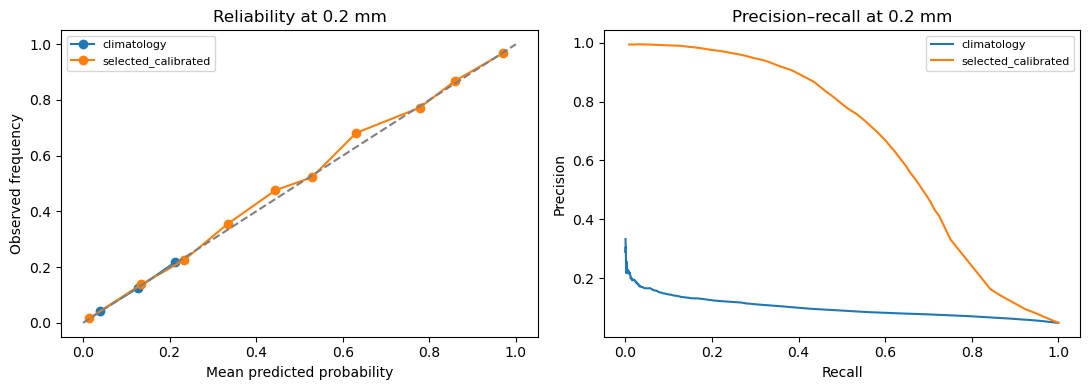

Metrics and scores saved under gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01/results
Figure saved to gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01/figures/task2/final_holdout_model_comparison.png
Download both task figure folders from the local repository root:
gcloud storage cp --recursive gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01/figures ./report/figures/


In [41]:
primary_threshold = primary_thresholds[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for row in evaluation_rows:
    name = row["model"]
    scores = test_scores[name]
    at_threshold = scores.where(F.col("threshold_mm") == primary_threshold)
    reliability = reliability_table(at_threshold).orderBy("bin").toPandas()
    axes[0].plot(
        reliability["predicted_probability"],
        reliability["observed_frequency"],
        marker="o",
        label=name,
    )
    curve = precision_recall_points(at_threshold)
    axes[1].plot(curve["recall"], curve["precision"], label=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(xlabel="Mean predicted probability", ylabel="Observed frequency")
axes[0].set_title(f"Reliability at {primary_threshold:g} mm")
axes[1].set(xlabel="Recall", ylabel="Precision")
axes[1].set_title(f"Precision–recall at {primary_threshold:g} mm")
for axis in axes:
    axis.legend(fontsize=8)
figure_local_dir = (
    Path(tempfile.gettempdir()) / "dsa5208-rainfall" / RUN_ID / "task2"
)
figure_local_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_local_dir / "final_holdout_model_comparison.png"
figure_gcs_path = f"{ROOT}/figures/task2/{figure_path.name}"
fig.tight_layout()
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
upload = subprocess.run(
    ["gcloud", "storage", "cp", str(figure_path), figure_gcs_path],
    capture_output=True,
    text=True,
)
if upload.returncode:
    message = upload.stderr.strip() or "Could not upload the final holdout figure."
    raise RuntimeError(message)
print(f"Metrics and scores saved under {RESULTS_ROOT}")
print(f"Figure saved to {figure_gcs_path}")
print("Download both task figure folders from the local repository root:")
print(f"gcloud storage cp --recursive {ROOT}/figures ./report/figures/")

for frame in [pilot, train, selection, training_stations, test, *test_scores.values()]:
    frame.unpersist()


## Monotonic probability extension — fixed methods

The original model selection and 2024 evaluation above are unchanged. Below we
train one additional **native MLlib multinomial logistic regression** model
on the same 2017–2022 sampled station-times. Its classes are
`{0}`, `(0,0.2]`, `(0.2,0.5]`, `(0.5,1]`, `(1,2]`, `(2,5]`, `(5,10]`,
`(10,20]`, `(20,infinity)` in millimetres. An empirical within-bin CDF is
estimated from **all** training targets. This supports strict exceedance
`P(Y > threshold)` on `[0,20]` mm without interpolation assumptions.

The second method uses the already fitted `gbt_B`, fits a separate global
isotonic **score calibrator** on 2023 H2, then performs a per-station-time
non-increasing isotonic projection on a fixed threshold grid. Between grid
points the prediction function is linearly interpolated. Its grid is part of
the inference contract, and is not claimed to be grid-independent.


In [42]:
# Frozen extension choices; do not tune them on 2024.
from bisect import bisect_right
from pyspark.sql.types import DoubleType
from pyspark.ml.linalg import Vectors

MONO_ROOT = f"{ROOT}/monotonic_extension"
BIN_EDGES_MM = [0.0, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
BIN_EDGES_UNITS = [threshold_units(v) for v in BIN_EDGES_MM]
MONO_EVAL_THRESHOLDS = sorted(set([0.0, 20.0] + config["thresholds_mm"] + config["unseen_thresholds_mm"]))
# Dense near small rainfall; contains all 11 previously evaluated thresholds.
MONO_GRID = sorted(set(MONO_EVAL_THRESHOLDS + [0.1, 0.4, 0.6, 0.8, 1.2, 1.75, 2.5, 4.0, 6.0, 8.5, 12.5, 15.0, 17.5]))
MONO_TEST_FRACTION = 0.002
MONO_CALIBRATION_FRACTION = 0.01
MONO_REG_PARAM = 0.05
assert len(BIN_EDGES_MM) == 8 and len(MONO_GRID) == len(set(MONO_GRID))
assert set(MONO_EVAL_THRESHOLDS).issubset(set(MONO_GRID))
assert max(MONO_GRID) <= BIN_EDGES_MM[-1]
print("Monotonic extension: 9 rainfall classes; fixed 0–20 mm domain")
print("Correction grid:", MONO_GRID)
print("Evaluation thresholds:", MONO_EVAL_THRESHOLDS)


Monotonic extension: 9 rainfall classes; fixed 0–20 mm domain
Correction grid: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.75, 0.8, 1.0, 1.2, 1.5, 1.75, 2.0, 2.5, 3.5, 4.0, 5.0, 6.0, 7.5, 8.5, 10.0, 12.5, 15.0, 17.5, 20.0]
Evaluation thresholds: [0.0, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.5, 5.0, 7.5, 10.0, 20.0]


In [43]:
# Small synthetic checks run before fitting any additional model.
def pav_nonincreasing(values):
    """Equal-weight least-squares projection onto non-increasing sequences."""
    blocks = []
    for v in values:
        blocks.append([float(v), 1, 1])  # weighted sum, weight, length
        while len(blocks) > 1 and blocks[-2][0] / blocks[-2][1] < blocks[-1][0] / blocks[-1][1]:
            b = blocks.pop()
            blocks[-1][0] += b[0]
            blocks[-1][1] += b[1]
            blocks[-1][2] += b[2]
    return [block[0] / block[1] for block in blocks for _ in range(block[2])]

def linear_monotone_interpolation(grid, values, x):
    if not (grid[0] <= x <= grid[-1]):
        raise ValueError("Threshold outside supported range")
    j = bisect_right(grid, x) - 1
    if j == len(grid) - 1 or grid[j] == x:
        return float(values[j])
    fraction = (x - grid[j]) / (grid[j + 1] - grid[j])
    return float(values[j] * (1 - fraction) + values[j + 1] * fraction)

assert pav_nonincreasing([0.8, 0.65, 0.7, 0.4]) == [0.8, 0.675, 0.675, 0.4]
assert pav_nonincreasing([0.9, 0.7, 0.4]) == [0.9, 0.7, 0.4]
assert abs(linear_monotone_interpolation([0, 1], [0.8, 0.4], 0.5) - 0.6) < 1e-12
print("Local projection and interpolation checks passed.")


Local projection and interpolation checks passed.


In [44]:
# Build empirical within-bin distributions using only the training period.
# A groupBy over the integer target avoids collecting 34 million individual rows.
frequency_rows = (
    train_base.groupBy("future_units").count().orderBy("future_units").collect()
)
if not frequency_rows:
    raise ValueError("No training rainfall targets for the empirical CDF")
# A compact dictionary is broadcast to executors, not the full training dataset.
counts_by_bin = [[] for _ in range(9)]
for row in frequency_rows:
    units = int(row["future_units"])
    if units == 0:
        j = 0
    else:
        j = next((k for k in range(1, len(BIN_EDGES_UNITS)) if units <= BIN_EDGES_UNITS[k]), 8)
    counts_by_bin[j].append((units, int(row["count"])))

cdf_lookup = []
for group in counts_by_bin:
    total = sum(n for _, n in group)
    if total <= 0:
        raise ValueError("Empty rainfall bin in the training period")
    running = 0
    xs, cumulative = [], []
    for units, count in group:
        running += count
        xs.append(units)
        cumulative.append(running / total)
    cdf_lookup.append((xs, cumulative))

cdf_broadcast = spark.sparkContext.broadcast(cdf_lookup)
print("Empirical CDF support sizes:", [len(group[0]) for group in cdf_lookup])
print("Training targets used for CDF:", sum(n for group in counts_by_bin for _, n in group))

# CDF lookup is fixed and unconditional within each bin; class probabilities
# depend on station/time/history. Equality is NOT an exceedance.
def empirical_exceedance(probabilities, threshold_units_value, lookup):
    if probabilities is None or len(probabilities) != 9:
        return None
    t = int(threshold_units_value)
    if t < 0 or t > BIN_EDGES_UNITS[-1]:
        return None
    j = 0 if t == 0 else next((k for k in range(1, 8) if t <= BIN_EDGES_UNITS[k]), 8)
    # For 0 <= t <= 20, the containing bin is 0..7.
    if j == 8:
        return float(probabilities[8])
    xs, cum = lookup[j]
    pos = bisect_right(xs, t) - 1
    fraction_above = 1.0 - (cum[pos] if pos >= 0 else 0.0)
    result = sum(float(v) for v in probabilities[j + 1:]) + float(probabilities[j]) * fraction_above
    return max(0.0, min(1.0, result))

# The zero-bin is a point mass: P(Y>0)=1-P(Y=0).
assert abs(empirical_exceedance([.6,.15,.12,.08,.02,.01,.01,.005,.005], 0, cdf_lookup) - .4) < 1e-10


Empirical CDF support sizes: [1, 3, 11, 17, 35, 105, 207, 676, 2441]
Training targets used for CDF: 34542285


In [45]:
# Train a native MLlib multinomial logistic regression on the same 2% time sample.
# No threshold expansion: one row per station/time, one of nine ordered bins.
def rainfall_bin_label(units_col):
    expr = F.when(units_col == 0, F.lit(0))
    for index in range(1, 8):
        expr = expr.when(units_col <= F.lit(BIN_EDGES_UNITS[index]), F.lit(index))
    return expr.otherwise(F.lit(8)).cast("double")

MULTI_FEATURES = [name for name in feature_columns("B") if name != "threshold_mm"]
multinomial_training = (
    deterministic_sample(train_base, config["final_train_fraction"])
    .withColumn("label", rainfall_bin_label(F.col("future_units")))
    .persist(StorageLevel.DISK_ONLY)
)
multinomial_support = multinomial_training.groupBy("label").count().orderBy("label").collect()
if len(multinomial_support) != 9:
    raise ValueError("At least one of the nine rainfall classes is absent")
display([r.asDict() for r in multinomial_support])

multi_imputed = [f"{name}_imputed" for name in MULTI_FEATURES]
multinomial_pipeline = Pipeline(stages=[
    StringIndexer(inputCol="station_id", outputCol="station_index", handleInvalid="keep"),
    OneHotEncoder(inputCols=["station_index"], outputCols=["station_vector"], handleInvalid="keep", dropLast=False),
    Imputer(inputCols=MULTI_FEATURES, outputCols=multi_imputed, strategy="median"),
    VectorAssembler(inputCols=["station_vector", *multi_imputed], outputCol="assembled"),
    StandardScaler(inputCol="assembled", outputCol="features", withMean=False, withStd=True),
    LogisticRegression(featuresCol="features", labelCol="label", family="multinomial",
                       maxIter=60, regParam=MONO_REG_PARAM, elasticNetParam=0.0),
])
multinomial_model = multinomial_pipeline.fit(multinomial_training)
multinomial_model.write().overwrite().save(f"{MONO_ROOT}/models/multinomial_B")
multinomial_training.unpersist()
print("Fitted and saved multinomial_B using native Spark MLlib.")


26/10/18 01:42:45 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


[{'label': 0.0, 'count': 649650},
 {'label': 1.0, 'count': 11052},
 {'label': 2.0, 'count': 7043},
 {'label': 3.0, 'count': 7061},
 {'label': 4.0, 'count': 5374},
 {'label': 5.0, 'count': 5034},
 {'label': 6.0, 'count': 2870},
 {'label': 7.0, 'count': 1901},
 {'label': 8.0, 'count': 714}]

Fitted and saved multinomial_B using native Spark MLlib.


In [46]:
# Calibrate the GBT-B score globally, without fitting separate threshold calibrators.
# This is independent of whether the original Notebook 03 selected GBT-B.
gbt_reference = finalists["gbt_B"]
mono_calibration_base = deterministic_sample(calibration_base, MONO_CALIBRATION_FRACTION)
mono_calibration_queries = expand_thresholds(mono_calibration_base)
mono_calibration_scores = score_model(
    gbt_reference, mark_unseen(mono_calibration_queries, training_stations)
)
mono_gbt_calibrator = IsotonicRegression(
    featuresCol="p", labelCol="label", predictionCol="calibrated_p", isotonic=True
).fit(mono_calibration_scores)
mono_gbt_calibrator.write().overwrite().save(f"{MONO_ROOT}/models/gbt_B_global_calibrator")
print("Fitted GBT-B global score calibration on a fixed 2023 H2 sample.")


Fitted GBT-B global score calibration on a fixed 2023 H2 sample.


## Final monotonic holdout comparison

This section uses 2024 only after both additional estimators and the GBT
calibrator have been fitted. The fixed 0.2% deterministic sample is the same
for every compared method. Evaluation includes original training thresholds,
unseen thresholds, and the domain endpoints; **no model is selected using the
2024 scores**. The original Notebook 03 full-holdout results above remain the
primary project comparison. The extension reports its smaller, paired cohort
separately.


In [47]:
# Score the GBT once per correction-grid threshold, and multinomial once
# per station/time. Reuse these predictions for every evaluation method.
mono_test_base = deterministic_sample(test_base, MONO_TEST_FRACTION).persist(StorageLevel.DISK_ONLY)
mono_test_count = mono_test_base.count()
if mono_test_count == 0:
    raise ValueError("Monotonicity evaluation sample is empty")
print("Monotonicity evaluation station-times:", mono_test_count)

mono_grid_queries = mark_unseen(expand_thresholds(mono_test_base, MONO_GRID), training_stations)
mono_raw_scores = score_model(gbt_reference, mono_grid_queries)
mono_gbt_scores = (
    mono_gbt_calibrator.transform(mono_raw_scores)
    .select(*SCORE_COLUMNS, F.col("calibrated_p").alias("p"))
    .persist(StorageLevel.DISK_ONLY)
)

# Use ordered arrays to project and interpolate on the full fixed grid.
@F.udf("array<double>")
def project_probabilities(values):
    return pav_nonincreasing(values)

@F.udf("double")
def interpolate_corrected(values, threshold):
    if values is None or threshold is None:
        return None
    return linear_monotone_interpolation(MONO_GRID, values, float(threshold))

curves = (
    mono_gbt_scores.groupBy("station_id", "epoch")
    .agg(F.sort_array(F.collect_list(F.struct("threshold_mm", "p"))).alias("points"))
    .withColumn("raw_curve", F.expr("transform(points, x -> x.p)"))
    .withColumn("corrected_curve", project_probabilities("raw_curve"))
    .select("station_id", "epoch", "corrected_curve")
)
mono_eval_queries = mark_unseen(
    expand_thresholds(mono_test_base, MONO_EVAL_THRESHOLDS), training_stations
).persist(StorageLevel.DISK_ONLY)

# Original GBT scores are taken from the same grid, not recomputed.
mono_original = (
    mono_gbt_scores.where(F.col("threshold_mm").isin(MONO_EVAL_THRESHOLDS))
    .select(*SCORE_COLUMNS, "p")
    .persist(StorageLevel.DISK_ONLY)
)
mono_corrected = (
    mono_eval_queries.join(curves, ["station_id", "epoch"], "inner")
    .withColumn("p", interpolate_corrected("corrected_curve", "threshold_mm"))
    .select(*SCORE_COLUMNS, "p")
    .persist(StorageLevel.DISK_ONLY)
)

@F.udf("double")
def bin_survival(probabilities, threshold_value):
    if probabilities is None or threshold_value is None:
        return None
    return empirical_exceedance(probabilities, threshold_value, cdf_broadcast.value)

mono_multi_probabilities = (
    multinomial_model.transform(mono_test_base)
    .select("station_id", "epoch", vector_to_array("probability").alias("bin_probabilities"))
)
mono_multinomial = (
    mono_eval_queries.join(mono_multi_probabilities, ["station_id", "epoch"], "inner")
    .withColumn("p", bin_survival("bin_probabilities", "threshold_units"))
    .select(*SCORE_COLUMNS, "p")
    .persist(StorageLevel.DISK_ONLY)
)
mono_scores = {
    "gbt_B_calibrated": mono_original,
    "gbt_B_threshold_isotonic": mono_corrected,
    "multinomial_B_empirical_cdf": mono_multinomial,
}
print("Constructed original, threshold-isotonic, and multinomial-CDF predictions.")


26/10/18 01:44:39 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Monotonicity evaluation station-times: 12776


26/10/18 01:44:43 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 01:44:44 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 01:44:44 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.
26/10/18 01:44:44 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


Constructed original, threshold-isotonic, and multinomial-CDF predictions.


26/10/18 01:44:45 WARN SimpleTableFunctionRegistry: The function read_files replaced a previously registered function.


In [48]:
# Paired validation, per-threshold probabilistic metrics, and monotonicity.
# The same station/time/threshold keys and strict-exceedance labels are required.
mono_expected_count = mono_test_count * len(MONO_EVAL_THRESHOLDS)
mono_evaluation = []
for name, scores in mono_scores.items():
    count = scores.count()
    if count != mono_expected_count:
        raise ValueError(f"{name}: expected {mono_expected_count} scores, got {count}")
    invalid = scores.where(F.col("p").isNull() | F.isnan("p") | (F.col("p") < 0) | (F.col("p") > 1))
    if invalid.limit(1).count():
        raise ValueError(f"{name}: invalid predicted probability")
    metrics = threshold_metrics(scores, MONO_EVAL_THRESHOLDS)
    monotonicity = monotonicity_summary(scores)
    if name != "gbt_B_calibrated" and (monotonicity["max_increase"] or 0) > config["monotonicity_tolerance"]:
        raise ValueError(f"{name}: monotonicity regression detected")
    row = {
        "model": name,
        "n_station_times": mono_test_count,
        "per_threshold": metrics,
        "ece": weighted_ece(scores),
        "monotonicity": monotonicity,
    }
    mono_evaluation.append(row)
    scores.write.mode("overwrite").parquet(f"{MONO_ROOT}/scores/{name}")
    reliability_table(scores).write.mode("overwrite").json(f"{MONO_ROOT}/reliability/{name}")

display([{
    "model": row["model"], "threshold_mm": metric["threshold_mm"],
    "pr_auc": metric["pr_auc"], "brier": metric["brier"],
    "f1_at_0_5": metric["f1"], "violation_rate": row["monotonicity"]["violation_rate"],
} for row in mono_evaluation for metric in row["per_threshold"]])

mono_summary = {
    "experiment": "monotonic_probability_extension",
    "fixed_training_bin_edges_mm": BIN_EDGES_MM,
    "correction_grid_mm": MONO_GRID,
    "evaluation_thresholds_mm": MONO_EVAL_THRESHOLDS,
    "supported_threshold_domain_mm": [0.0, 20.0],
    "multinomial_reg_param": MONO_REG_PARAM,
    "test_sample_fraction": MONO_TEST_FRACTION,
    "calibration_sample_fraction": MONO_CALIBRATION_FRACTION,
    "train_sample_fraction": config["final_train_fraction"],
    "empirical_cdf_source": "all valid 2017-2022 targets",
    "post_test_tuning": False,
    "results": mono_evaluation,
}
summary_json = json.dumps(mono_summary, allow_nan=False)
spark.createDataFrame([(summary_json,)], "value string").coalesce(1).write.mode("overwrite").text(
    f"{MONO_ROOT}/evaluation_summary"
)
print("Saved monotonic extension results under", MONO_ROOT)


[{'model': 'gbt_B_calibrated',
  'threshold_mm': 0.0,
  'pr_auc': 0.6571352699526047,
  'brier': 0.03387685199643347,
  'f1_at_0_5': 0.5533731853116994,
  'violation_rate': 1.3045293258192444e-05},
 {'model': 'gbt_B_calibrated',
  'threshold_mm': 0.2,
  'pr_auc': 0.6590110459219561,
  'brier': 0.02535766997422994,
  'f1_at_0_5': 0.5987903225806452,
  'violation_rate': 1.3045293258192444e-05},
 {'model': 'gbt_B_calibrated',
  'threshold_mm': 0.3,
  'pr_auc': 0.6361640179841588,
  'brier': 0.024468772907014037,
  'f1_at_0_5': 0.591728525980912,
  'violation_rate': 1.3045293258192444e-05},
 {'model': 'gbt_B_calibrated',
  'threshold_mm': 0.5,
  'pr_auc': 0.6308540493574639,
  'brier': 0.02081431276817591,
  'f1_at_0_5': 0.6055276381909548,
  'violation_rate': 1.3045293258192444e-05},
 {'model': 'gbt_B_calibrated',
  'threshold_mm': 0.75,
  'pr_auc': 0.6135593602920099,
  'brier': 0.018995249330528728,
  'f1_at_0_5': 0.6024759284731774,
  'violation_rate': 1.3045293258192444e-05},
 {'model

Saved monotonic extension results under gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01/monotonic_extension


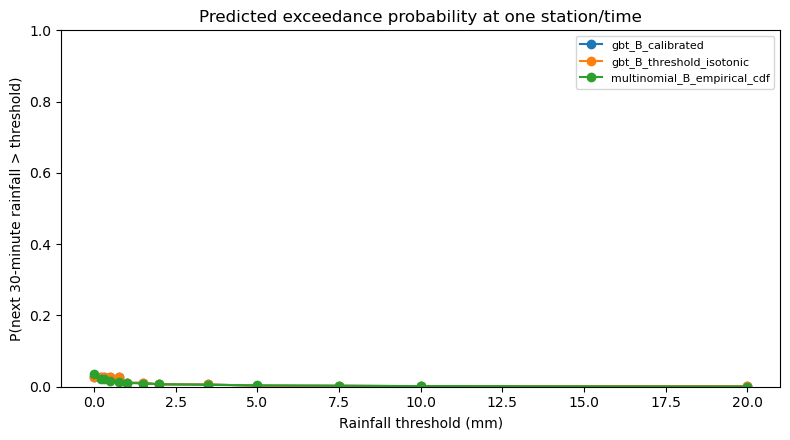

Copying file:///tmp/dsa5208-rainfall/20261018-monotonic-01/task2/monotonic_probability_comparison.png to gs://dsa5208-rainfall-project-2-data/runs/20261018-monotonic-01/monotonic_extension/figures/monotonic_probability_comparison.png
  
.


Monotonic extension complete; original Notebook 03 outputs are retained.


In [49]:
# Representative probability curves and a compact report-ready comparison.
# Choose a deterministic example, not the visually best/worst 2024 case.
example = mono_test_base.select("station_id", "epoch").orderBy("station_id", "epoch").first()
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, scores in mono_scores.items():
    points = (
        scores.where((F.col("station_id") == example["station_id"]) &
                     (F.col("epoch") == example["epoch"]))
        .orderBy("threshold_mm").select("threshold_mm", "p").collect()
    )
    ax.plot([r["threshold_mm"] for r in points], [r["p"] for r in points],
            marker="o", label=name)
ax.set(xlabel="Rainfall threshold (mm)", ylabel="P(next 30-minute rainfall > threshold)",
       title="Predicted exceedance probability at one station/time")
ax.set_ylim(0, 1)
ax.legend(fontsize=8)
fig.tight_layout()
figure_local_dir = Path(tempfile.gettempdir()) / "dsa5208-rainfall" / RUN_ID / "task2"
figure_local_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_local_dir / "monotonic_probability_comparison.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)
subprocess.run(["gcloud", "storage", "cp", str(figure_path),
                f"{MONO_ROOT}/figures/{figure_path.name}"], check=True)

for frame in [mono_test_base, mono_grid_queries, mono_eval_queries, mono_gbt_scores, *mono_scores.values()]:
    try:
        frame.unpersist()
    except Exception:
        pass
print("Monotonic extension complete; original Notebook 03 outputs are retained.")
